shape: (5568, 3712, 3)
dtype: uint8
min: 0, max: 255


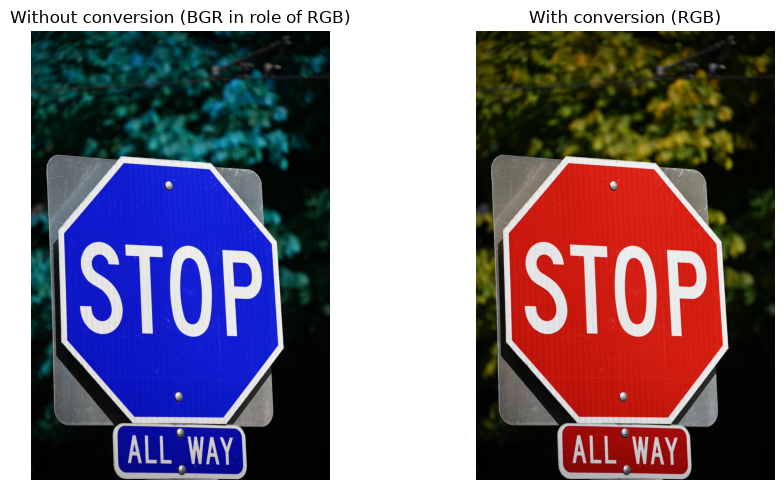

Amount of overflowed values in channels: 8028810


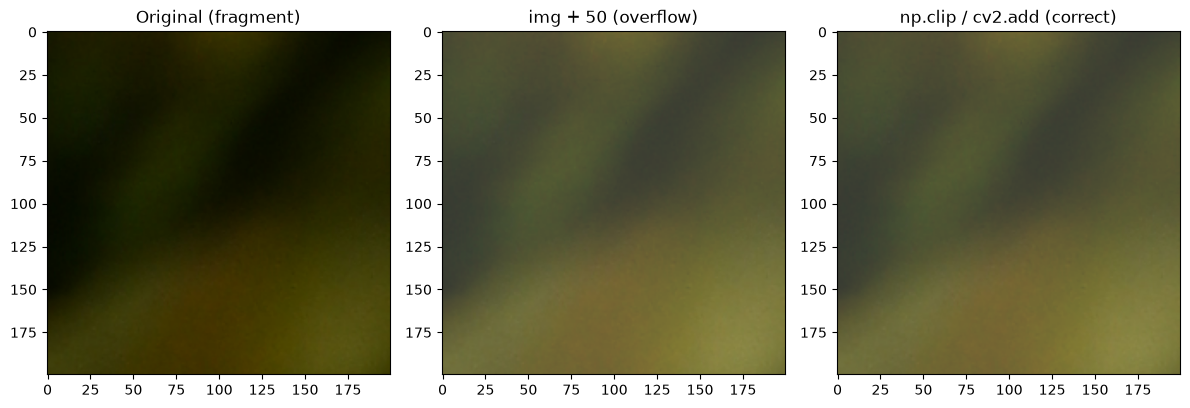

Format / Quality  File Size (KB)  PSNR (dB)
PNG (без потерь)    28499.527344        inf
         JPEG 95     4992.439453  44.162910
         JPEG 75     1804.314453  39.815261
         JPEG 50     1238.842773  37.603958
         JPEG 25      834.408203  34.920763
         JPEG 10      492.351562  30.683589


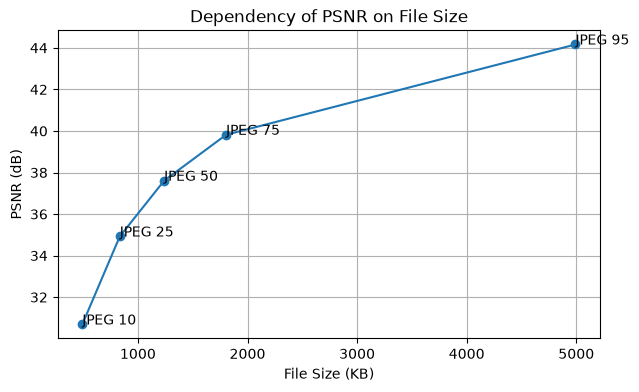

Focal Length: 150.0
Exposure Time: 0.001
ISO Speed Ratings: 100


In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ExifTags

img = cv2.imread('../data/image.jpg')

print(f"shape: {img.shape}")
print(f"dtype: {img.dtype}")
print(f"min: {img.min()}, max: {img.max()}")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Without conversion (BGR in role of RGB)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_rgb)
plt.title("With conversion (RGB)")
plt.axis('off')
plt.tight_layout()
plt.show()

bright_bad = img_rgb + 50

overflow_mask = (img_rgb > 205) & (bright_bad < 50)
print(f"Amount of overflowed values in channels: {np.sum(overflow_mask)}")

bright_cv2 = cv2.add(img_rgb, np.full(img_rgb.shape, 50, dtype=np.uint8))

bright_clip = np.clip(img_rgb.astype(np.int16) + 50, 0, 255).astype(np.uint8)

h, w, _ = img_rgb.shape
crop_y, crop_x = slice(0, min(200, h)), slice(0, min(200, w))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img_rgb[crop_y, crop_x])
plt.title("Original (fragment)")

plt.subplot(1, 3, 2)
plt.imshow(bright_bad[crop_y, crop_x])
plt.title("img + 50 (overflow)")

plt.subplot(1, 3, 3)
plt.imshow(bright_clip[crop_y, crop_x])
plt.title("np.clip / cv2.add (correct)")
plt.tight_layout()
plt.show()

def calculate_psnr(orig, compressed):
    mse = np.mean((orig.astype(np.float64) - compressed.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    return 10 * np.log10((255.0 ** 2) / mse)

results = []

png_file = '../figures/compressed.png'
cv2.imwrite(png_file, img)
img_png = cv2.imread(png_file)
results.append({
    'Format / Quality': 'PNG (без потерь)',
    'File Size (KB)': os.path.getsize(png_file) / 1024,
    'PSNR (dB)': calculate_psnr(img, img_png)
})

qualities = [95, 75, 50, 25, 10]
for q in qualities:
    jpg_file = f'../figures/compressed_q{q}.jpg'
    cv2.imwrite(jpg_file, img, [cv2.IMWRITE_JPEG_QUALITY, q])
    img_jpg = cv2.imread(jpg_file)
    results.append({
        'Format / Quality': f'JPEG {q}',
        'File Size (KB)': os.path.getsize(jpg_file) / 1024,
        'PSNR (dB)': calculate_psnr(img, img_jpg)
    })

df_psnr = pd.DataFrame(results)
print(df_psnr.to_string(index=False))

jpeg_df = df_psnr[df_psnr['Format / Quality'] != 'PNG (без потерь)']
plt.figure(figsize=(7, 4))
plt.plot(jpeg_df['File Size (KB)'], jpeg_df['PSNR (dB)'], marker='o')
for _, row in jpeg_df.iterrows():
    plt.annotate(row['Format / Quality'], (row['File Size (KB)'], row['PSNR (dB)']))
plt.xlabel('File Size (KB)')
plt.ylabel('PSNR (dB)')
plt.title('Dependency of PSNR on File Size')
plt.grid(True)
plt.show()

pil_img = Image.open('../data/image.jpg')
exif_data = pil_img._getexif()

if exif_data:
    exif = {ExifTags.TAGS.get(k, k): v for k, v in exif_data.items()}
    print("Focal Length:", exif.get('FocalLength'))
    print("Exposure Time:", exif.get('ExposureTime'))
    print("ISO Speed Ratings:", exif.get('ISOSpeedRatings'))
else:
    print("EXIF data not found (use the original photo from the camera/phone without relaying through messengers).")

In [3]:
frame1_bgr = cv2.imread('../data/frame1.jpg')
frame2_bgr = cv2.imread('../data/frame2.jpg')

gt_mask1 = (cv2.imread('../data/mask1.png', cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
gt_mask2 = (cv2.imread('../data/mask2.png', cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)

def compute_metrics(pred_mask, gt_mask):
    pred = (pred_mask > 0).astype(np.uint8)
    gt = (gt_mask > 0).astype(np.uint8)

    accuracy = np.mean(pred == gt)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    iou = intersection / union if union > 0 else 0.0
    return accuracy, iou

frame1_rgb = cv2.cvtColor(frame1_bgr, cv2.COLOR_BGR2RGB)
frame2_rgb = cv2.cvtColor(frame2_bgr, cv2.COLOR_BGR2RGB)

rgb_low = np.array([150, 20, 20], dtype=np.uint8)
rgb_high = np.array([255, 100, 100], dtype=np.uint8)

mask1_rgb = cv2.inRange(frame1_rgb, rgb_low, rgb_high)
mask2_rgb = cv2.inRange(frame2_rgb, rgb_low, rgb_high)

acc1_rgb, iou1_rgb = compute_metrics(mask1_rgb, gt_mask1)
acc2_rgb, iou2_rgb = compute_metrics(mask2_rgb, gt_mask2)

frame1_hsv = cv2.cvtColor(frame1_bgr, cv2.COLOR_BGR2HSV)
frame2_hsv = cv2.cvtColor(frame2_bgr, cv2.COLOR_BGR2HSV)

hsv_low = np.array([100, 80, 50], dtype=np.uint8)
hsv_high = np.array([130, 255, 255], dtype=np.uint8)

mask1_hsv = cv2.inRange(frame1_hsv, hsv_low, hsv_high)
mask2_hsv = cv2.inRange(frame2_hsv, hsv_low, hsv_high)

acc1_hsv, iou1_hsv = compute_metrics(mask1_hsv, gt_mask1)
acc2_hsv, iou2_hsv = compute_metrics(mask2_hsv, gt_mask2)

summary_df = pd.DataFrame([
    {'Space': 'RGB', 'Frame 1 (Acc)': f"{acc1_rgb:.4f}", 'Frame 1 (IoU)': f"{iou1_rgb:.4f}", 'Frame 2 (Acc)': f"{acc2_rgb:.4f}", 'Frame 2 (IoU)': f"{iou2_rgb:.4f}"},
    {'Space': 'HSV', 'Frame 1 (Acc)': f"{acc1_hsv:.4f}", 'Frame 1 (IoU)': f"{iou1_hsv:.4f}", 'Frame 2 (Acc)': f"{acc2_hsv:.4f}", 'Frame 2 (IoU)': f"{iou2_hsv:.4f}"}
])
print(summary_df.to_string(index=False))

Space Frame 1 (Acc) Frame 1 (IoU) Frame 2 (Acc) Frame 2 (IoU)
  RGB        0.8282        0.0071        0.8769        0.0000
  HSV        0.8662        0.0000        0.8769        0.0000


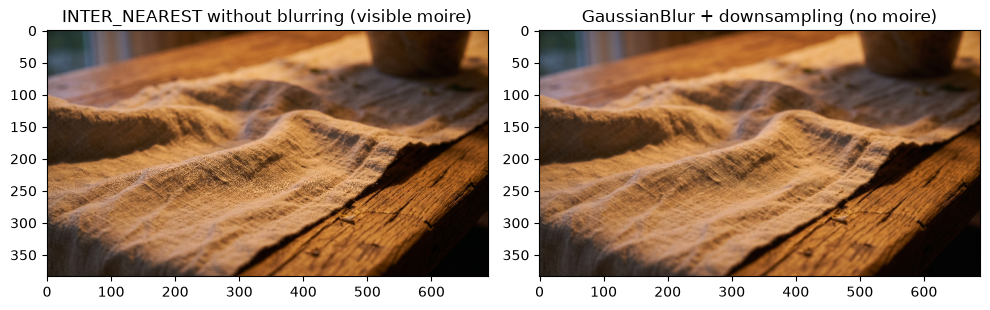

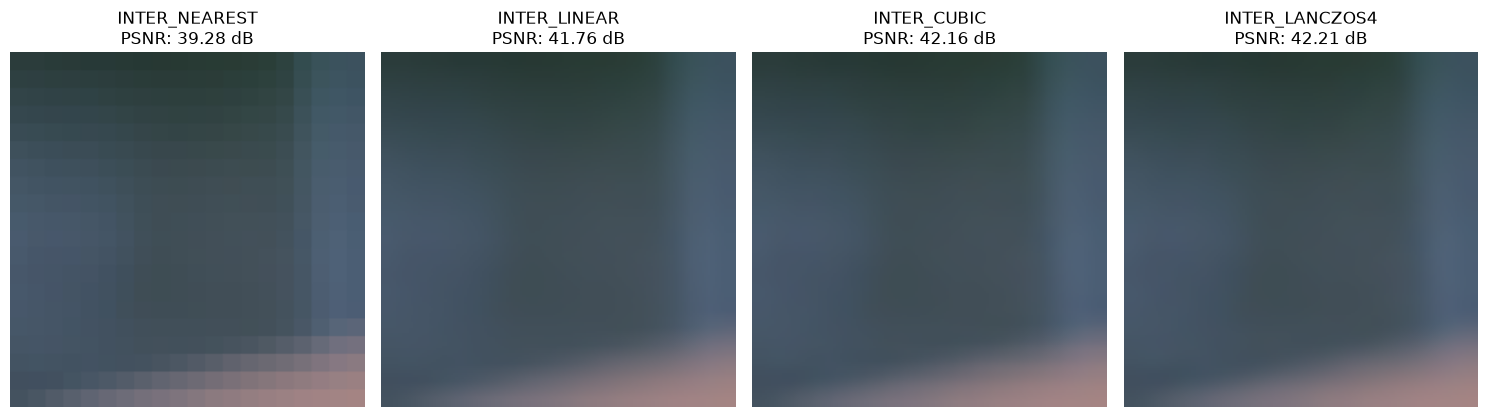

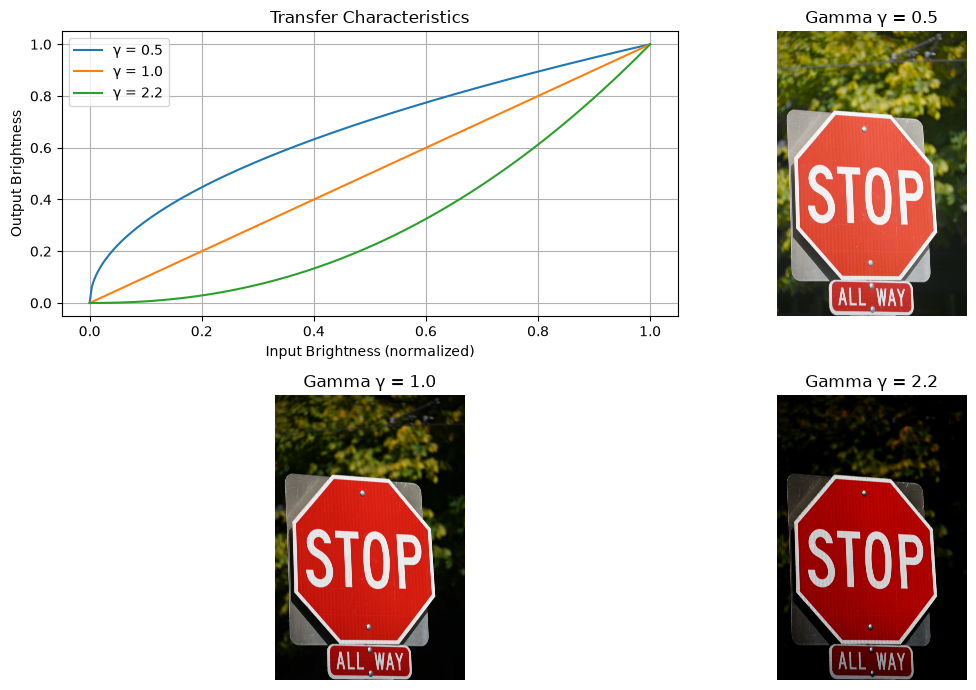

In [4]:
tex_img = cv2.cvtColor(cv2.imread('../data/texture.jpg'), cv2.COLOR_BGR2RGB)
h, w, _ = tex_img.shape
new_size = (w // 4, h // 4)

down_nearest = cv2.resize(tex_img, new_size, interpolation=cv2.INTER_NEAREST)

blurred = cv2.GaussianBlur(tex_img, (9, 9), sigmaX=2.0)
down_aa = cv2.resize(blurred, new_size, interpolation=cv2.INTER_NEAREST)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(down_nearest)
plt.title("INTER_NEAREST without blurring (visible moire)")
plt.subplot(1, 2, 2)
plt.imshow(down_aa)
plt.title("GaussianBlur + downsampling (no moire)")
plt.tight_layout()
plt.show()

patch_hr = tex_img[100:260, 100:260]
ph, pw, _ = patch_hr.shape

patch_lr = cv2.resize(patch_hr, (pw // 8, ph // 8), interpolation=cv2.INTER_AREA)

methods = {
    'INTER_NEAREST': cv2.INTER_NEAREST,
    'INTER_LINEAR': cv2.INTER_LINEAR,
    'INTER_CUBIC': cv2.INTER_CUBIC,
    'INTER_LANCZOS4': cv2.INTER_LANCZOS4
}

plt.figure(figsize=(15, 4))
for idx, (name, flag) in enumerate(methods.items(), 1):
    upscaled = cv2.resize(patch_lr, (pw, ph), interpolation=flag)
    psnr_val = calculate_psnr(patch_hr, upscaled)
    
    plt.subplot(1, 4, idx)
    plt.imshow(upscaled)
    plt.title(f"{name}\nPSNR: {psnr_val:.2f} dB")
    plt.axis('off')
plt.tight_layout()
plt.show()

gammas = [0.5, 1.0, 2.2]
x = np.linspace(0, 1, 256)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
for g in gammas:
    plt.plot(x, x ** g, label=f'γ = {g}')
plt.title("Transfer Characteristics")
plt.xlabel("Input Brightness (normalized)")
plt.ylabel("Output Brightness")
plt.legend()
plt.grid(True)

img_norm = img_rgb.astype(np.float32) / 255.0
for idx, g in enumerate(gammas, 2):
    gamma_corrected = np.clip((img_norm ** g) * 255.0, 0, 255).astype(np.uint8)
    plt.subplot(2, 2, idx)
    plt.imshow(gamma_corrected)
    plt.title(f"Gamma γ = {g}")
    plt.axis('off')

plt.tight_layout()
plt.show()